# 📊 Analisis Sentimen Lagu "Arteri" - .FEAST
## Menggunakan Support Vector Machine (SVM) dengan TF-IDF

---

**Author:** Rafi Maulana Firdaus (312210382)  
**Keperluan:** Seminar Proposal (SEMPRO)  
**Universitas:** Pelita Bangsa  
**Tanggal:** Februari 2026

---

### Metodologi:
1. **Pengumpulan Data** - Scraping komentar YouTube
2. **Preprocessing** - Pembersihan dan normalisasi teks  
3. **Labeling** - Pelabelan sentimen (positif/negatif/netral)
4. **Feature Extraction** - TF-IDF Vectorization
5. **Modeling** - Support Vector Machine (SVM)
6. **Evaluasi** - Accuracy, Precision, Recall, F1-Score

## 1. Import Libraries

In [47]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report, confusion_matrix, 
    accuracy_score, precision_score, recall_score, f1_score
)
from sklearn.utils.class_weight import compute_class_weight

# Untuk menyimpan model
import joblib
import os

print("✅ Libraries berhasil diimport!")
print(f"   - pandas: {pd.__version__}")
print(f"   - numpy: {np.__version__}")
print(f"   - scikit-learn: imported")

✅ Libraries berhasil diimport!
   - pandas: 2.3.3
   - numpy: 2.4.1
   - scikit-learn: imported


## 2. Load Data

Memuat data yang sudah dilabeli dari tahap sebelumnya.

In [48]:
# Load labeled data
data_path = "../Data/comments_labeled.csv"

if os.path.exists(data_path):
    df = pd.read_csv(data_path)
    print(f"✅ Data berhasil dimuat: {len(df)} baris")
else:
    print(f"❌ File tidak ditemukan: {data_path}")
    print("   Jalankan preprocessing.py dan labeling.py terlebih dahulu!")

✅ Data berhasil dimuat: 820 baris


In [49]:
# Tampilkan info data
print("\n📋 Info Dataset:")
print("-" * 40)
print(df.info())
print("\n📊 Statistik Deskriptif:")
df.describe()


📋 Info Dataset:
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 820 entries, 0 to 819
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   no                   820 non-null    int64  
 1   author               820 non-null    object 
 2   text                 820 non-null    object 
 3   text_processed       820 non-null    object 
 4   sentiment            820 non-null    object 
 5   sentiment_score      820 non-null    float64
 6   sentiment_label      820 non-null    int64  
 7   positive_word_count  820 non-null    int64  
 8   negative_word_count  820 non-null    int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 57.8+ KB
None

📊 Statistik Deskriptif:


,no,sentiment_score,sentiment_label,positive_word_count,negative_word_count
count,820.000000,820.000000,820.000000,820.000000,820.000000
mean,410.500000,0.833720,1.312195,0.668293,0.265854
std,236.857904,1.806426,0.650047,0.940070,0.664873
min,1.000000,-5.000000,0.000000,0.000000,0.000000
25%,205.750000,0.000000,1.000000,0.000000,0.000000
50%,410.500000,0.000000,1.000000,0.000000,0.000000
75%,615.250000,1.500000,2.000000,1.000000,0.000000
max,820.000000,13.500000,2.000000,7.000000,5.000000


In [50]:
# Tampilkan sample data
print("\n📝 Sample Data (5 baris pertama):")
df.head()


📝 Sample Data (5 baris pertama):


,no,author,text,text_processed,sentiment,sentiment_score,sentiment_label,positive_word_count,negative_word_count
0,1,@CYM-Change_Your_Mindset,konsepnya sama lah kek lagu bunny girl,konsep sama kayak lagu bunny girl,netral,0.0,1,0,0
1,2,@rasi3625,my soooong anying,my soooong gila,netral,0.0,1,0,0
2,3,@Nuraenimistaa,"Dunia gak cuma pondok indah bas, ada juga Cis...",dunia pondok indah bas cisauk sepat kresek ten...,positif,3.0,2,2,0
3,4,@MuhammadFahmi-el3qj,POV jule,pov jule,netral,0.0,1,0,0
4,5,@Putra212-e5c,keren banget bang,bagus banget,positif,4.5,2,2,0


## 3. Exploratory Data Analysis (EDA)

### 3.1 Distribusi Sentimen

In [51]:
# Mapping label numerik ke nama
label_names = {0: 'Negatif', 1: 'Netral', 2: 'Positif'}
df['sentiment_name'] = df['sentiment_label'].map(label_names)

# Hitung distribusi
sentiment_dist = df['sentiment_name'].value_counts()
print("\n📊 Distribusi Sentimen:")
print("-" * 40)
for sentiment, count in sentiment_dist.items():
    pct = count / len(df) * 100
    print(f"   {sentiment}: {count} ({pct:.1f}%)")


📊 Distribusi Sentimen:
----------------------------------------
   Netral: 394 (48.0%)
   Positif: 341 (41.6%)
   Negatif: 85 (10.4%)


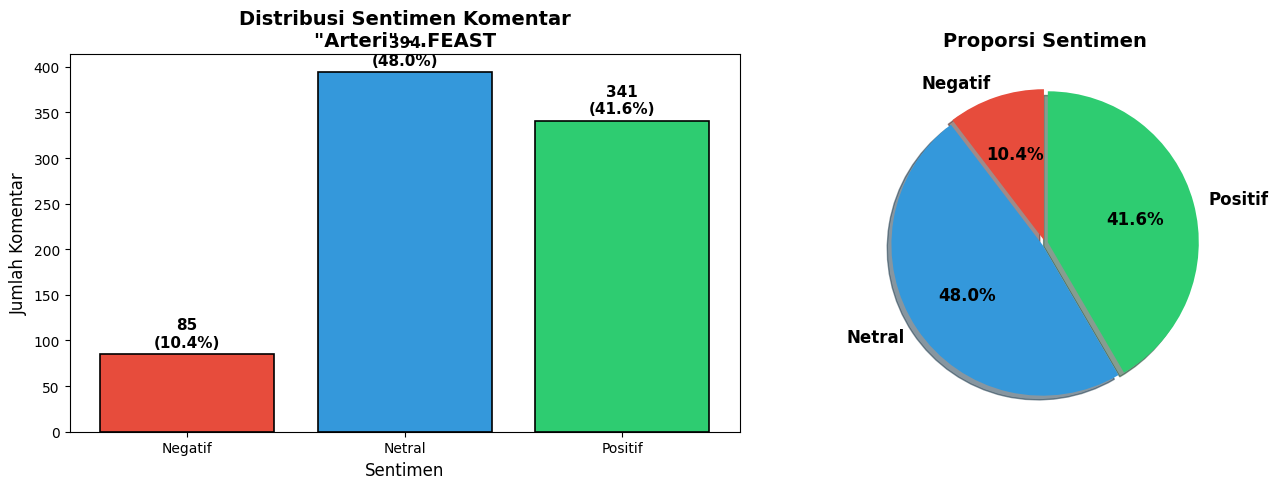


✅ Grafik tersimpan: Output/distribusi_sentimen.png


In [52]:
# Visualisasi distribusi sentimen
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
colors = ['#e74c3c', '#3498db', '#2ecc71']  # Negatif, Netral, Positif
sentiment_order = ['Negatif', 'Netral', 'Positif']
counts = [sentiment_dist.get(s, 0) for s in sentiment_order]

bars = axes[0].bar(sentiment_order, counts, color=colors, edgecolor='black', linewidth=1.2)
axes[0].set_title('Distribusi Sentimen Komentar\n"Arteri" - .FEAST', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Sentimen', fontsize=12)
axes[0].set_ylabel('Jumlah Komentar', fontsize=12)

# Add value labels
for bar, count in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5, 
                 f'{count}\n({count/len(df)*100:.1f}%)', 
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

# Pie chart
axes[1].pie(counts, labels=sentiment_order, colors=colors, autopct='%1.1f%%',
            startangle=90, explode=(0.02, 0.02, 0.02), shadow=True,
            textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[1].set_title('Proporsi Sentimen', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../Output/distribusi_sentimen.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Grafik tersimpan: Output/distribusi_sentimen.png")

## 4. Persiapan Data untuk Model

### 4.1 Ekstraksi Fitur dan Label

In [53]:
# Ekstrak teks dan label
X = df['text_processed'].astype(str).values
y = df['sentiment_label'].values

print(f"\n📊 Data untuk modeling:")
print(f"   - Total sampel: {len(X)}")
print(f"   - Fitur: text_processed")
print(f"   - Target: sentiment_label (0=Negatif, 1=Netral, 2=Positif)")


📊 Data untuk modeling:
   - Total sampel: 820
   - Fitur: text_processed
   - Target: sentiment_label (0=Negatif, 1=Netral, 2=Positif)


### 4.2 Pembagian Data (Train-Test Split)

Data dibagi menjadi 80% training dan 20% testing dengan stratified sampling.

In [54]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42,
    stratify=y  # Menjaga proporsi kelas
)

print(f"\n📊 Pembagian Data:")
print(f"   - Training: {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)")
print(f"   - Testing: {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)")

# Cek distribusi di training
print(f"\n   Distribusi di Training:")
unique, counts = np.unique(y_train, return_counts=True)
for u, c in zip(unique, counts):
    print(f"      {label_names[u]}: {c} ({c/len(y_train)*100:.1f}%)")


📊 Pembagian Data:
   - Training: 656 (80.0%)
   - Testing: 164 (20.0%)

   Distribusi di Training:
      Negatif: 68 (10.4%)
      Netral: 315 (48.0%)
      Positif: 273 (41.6%)


## 5. Feature Extraction dengan TF-IDF

**TF-IDF (Term Frequency-Inverse Document Frequency)** mengkonversi teks menjadi vektor numerik dengan memperhatikan:
- **TF**: Frekuensi kata dalam dokumen
- **IDF**: Kebalikan frekuensi dokumen (mengurangi bobot kata umum)

In [55]:
# Konfigurasi TF-IDF
tfidf_config = {
    'max_features': 5000,      # Vocabulary size maksimal
    'ngram_range': (1, 2),     # Unigram + Bigram
    'min_df': 2,               # Minimum document frequency
    'max_df': 0.95,            # Maximum document frequency
    'sublinear_tf': True       # Log scaling untuk TF
}

print("\n⚙️ Konfigurasi TF-IDF:")
for key, value in tfidf_config.items():
    print(f"   - {key}: {value}")


⚙️ Konfigurasi TF-IDF:
   - max_features: 5000
   - ngram_range: (1, 2)
   - min_df: 2
   - max_df: 0.95
   - sublinear_tf: True


In [56]:
# Buat dan fit TF-IDF Vectorizer
vectorizer = TfidfVectorizer(**tfidf_config)

# Fit pada training data, transform both
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"\n✅ TF-IDF Vectorization selesai!")
print(f"   - Vocabulary size: {len(vectorizer.vocabulary_)}")
print(f"   - Training matrix: {X_train_tfidf.shape}")
print(f"   - Testing matrix: {X_test_tfidf.shape}")


✅ TF-IDF Vectorization selesai!
   - Vocabulary size: 738
   - Training matrix: (656, 738)
   - Testing matrix: (164, 738)


In [57]:
# Tampilkan contoh fitur (top 20)
feature_names = vectorizer.get_feature_names_out()
print(f"\n📝 Contoh Fitur TF-IDF (20 pertama):")
print("-" * 40)
for i, feat in enumerate(feature_names[:20], 1):
    print(f"   {i:2d}. {feat}")


📝 Contoh Fitur TF-IDF (20 pertama):
----------------------------------------
    1. 19
    2. 20
    3. 2025
    4. 20an
    5. 24
    6. 30
    7. 500
    8. 500 days
    9. abang
   10. abis
   11. ada
   12. adiksi
   13. air
   14. aja
   15. ajar
   16. akal
   17. akhir
   18. aku
   19. aku lari
   20. alam


## 6. Model Support Vector Machine (SVM)

### 6.1 Hyperparameter Tuning dengan GridSearchCV

SVM akan dioptimalkan dengan mencari kombinasi terbaik dari:
- **Kernel**: linear, rbf
- **C**: Parameter regularisasi
- **Gamma**: Koefisien kernel (untuk RBF)

In [58]:
# Konfigurasi GridSearchCV
param_grid = {
    'kernel': ['linear', 'rbf'],
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto']
}

print("\n⚙️ Parameter Grid untuk GridSearchCV:")
for key, values in param_grid.items():
    print(f"   - {key}: {values}")
print(f"\n   Total kombinasi: {len(param_grid['kernel']) * len(param_grid['C']) * len(param_grid['gamma'])}")


⚙️ Parameter Grid untuk GridSearchCV:
   - kernel: ['linear', 'rbf']
   - C: [0.1, 1, 10]
   - gamma: ['scale', 'auto']

   Total kombinasi: 12


In [59]:
# Hitung class weights untuk handling imbalanced data
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))

print("\n⚖️ Class Weights (untuk imbalanced data):")
for label, weight in class_weight_dict.items():
    print(f"   - {label_names[label]}: {weight:.4f}")


⚖️ Class Weights (untuk imbalanced data):
   - Negatif: 3.2157
   - Netral: 0.6942
   - Positif: 0.8010


In [60]:
# Build dan train model dengan GridSearchCV
print("\n🔄 Memulai GridSearchCV... (mungkin memakan waktu beberapa menit)")

# Base SVM model
svm_base = SVC(random_state=42, probability=True, class_weight='balanced')

# GridSearchCV
grid_search = GridSearchCV(
    svm_base,
    param_grid,
    cv=5,                    # 5-fold cross validation
    scoring='f1_weighted',   # Optimasi berdasarkan F1-Score
    n_jobs=-1,               # Gunakan semua CPU cores
    verbose=1
)

# Fit
import time
start_time = time.time()
grid_search.fit(X_train_tfidf, y_train)
training_time = time.time() - start_time

print(f"\n✅ Training selesai dalam {training_time:.2f} detik")


🔄 Memulai GridSearchCV... (mungkin memakan waktu beberapa menit)
Fitting 5 folds for each of 12 candidates, totalling 60 fits



✅ Training selesai dalam 1.13 detik


In [61]:
# Hasil GridSearchCV
print("\n🏆 Hasil GridSearchCV:")
print("=" * 50)
print(f"\n   Best Parameters:")
for key, value in grid_search.best_params_.items():
    print(f"      - {key}: {value}")
print(f"\n   Best CV Score (F1-Weighted): {grid_search.best_score_*100:.2f}%")

# Best model
best_model = grid_search.best_estimator_


🏆 Hasil GridSearchCV:

   Best Parameters:
      - C: 10
      - gamma: scale
      - kernel: linear

   Best CV Score (F1-Weighted): 72.15%


## 7. Evaluasi Model

### 7.1 Prediksi pada Data Test

In [62]:
# Prediksi
y_pred = best_model.predict(X_test_tfidf)
y_pred_proba = best_model.predict_proba(X_test_tfidf)

print("✅ Prediksi selesai!")
print(f"   - Total prediksi: {len(y_pred)}")

✅ Prediksi selesai!
   - Total prediksi: 164


### 7.2 Metrik Evaluasi

In [63]:
# Hitung metrik
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

print("\n" + "=" * 50)
print("📊 HASIL EVALUASI MODEL SVM")
print("=" * 50)
print(f"\n   Accuracy            : {accuracy*100:.2f}%")
print(f"   Precision (Weighted) : {precision*100:.2f}%")
print(f"   Recall (Weighted)    : {recall*100:.2f}%")
print(f"   F1-Score (Macro)     : {f1_macro*100:.2f}%")
print(f"   F1-Score (Weighted)  : {f1_weighted*100:.2f}%")
print("\n" + "=" * 50)


📊 HASIL EVALUASI MODEL SVM

   Accuracy            : 72.56%
   Precision (Weighted) : 73.17%
   Recall (Weighted)    : 72.56%
   F1-Score (Macro)     : 62.81%
   F1-Score (Weighted)  : 72.67%



In [64]:
# Classification Report
print("\n📋 CLASSIFICATION REPORT:")
print("-" * 60)
print(classification_report(y_test, y_pred, target_names=['Negatif', 'Netral', 'Positif']))


📋 CLASSIFICATION REPORT:
------------------------------------------------------------
              precision    recall  f1-score   support

     Negatif       0.33      0.35      0.34        17
      Netral       0.74      0.81      0.78        79
     Positif       0.82      0.72      0.77        68

    accuracy                           0.73       164
   macro avg       0.63      0.63      0.63       164
weighted avg       0.73      0.73      0.73       164



### 7.3 Confusion Matrix

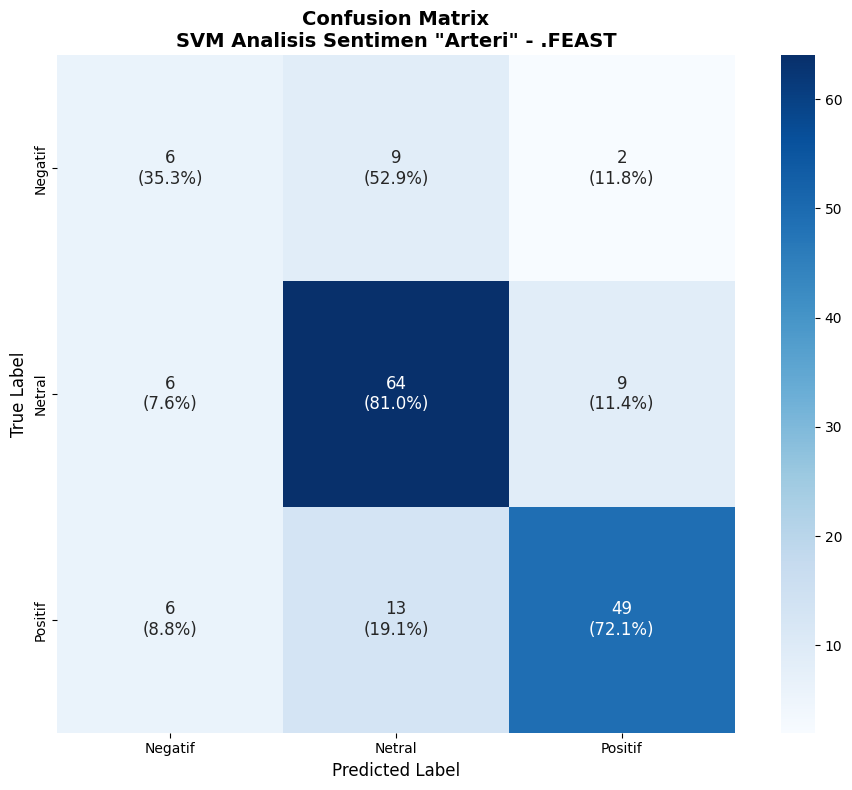


✅ Confusion matrix tersimpan: Output/confusion_matrix.png


In [65]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Plot
fig, ax = plt.subplots(figsize=(10, 8))

# Normalize
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Create annotations
labels_text = np.asarray([
    [f'{cm[i,j]}\n({cm_normalized[i,j]*100:.1f}%)' 
     for j in range(cm.shape[1])] 
    for i in range(cm.shape[0])
])

sns.heatmap(cm, annot=labels_text, fmt='', cmap='Blues',
            xticklabels=['Negatif', 'Netral', 'Positif'],
            yticklabels=['Negatif', 'Netral', 'Positif'],
            annot_kws={'size': 12}, square=True, ax=ax)

ax.set_title('Confusion Matrix\nSVM Analisis Sentimen "Arteri" - .FEAST', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)

plt.tight_layout()
plt.savefig('../Output/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Confusion matrix tersimpan: Output/confusion_matrix.png")

### 7.4 Visualisasi Metrik

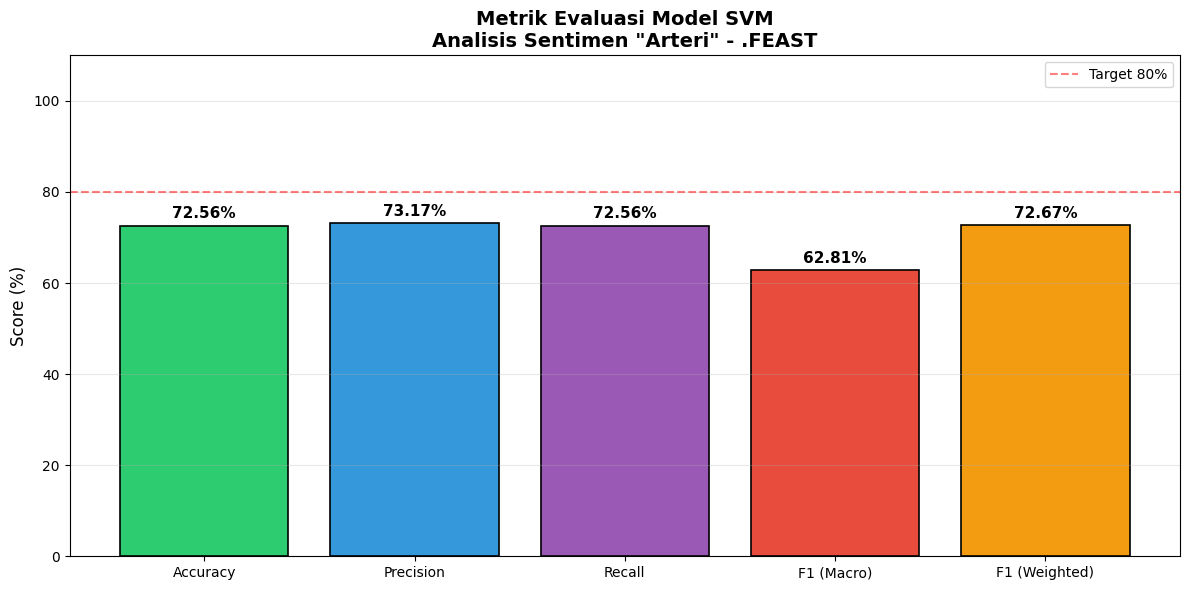


✅ Grafik metrik tersimpan: Output/metrics_comparison.png


In [66]:
# Plot metrik
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 (Macro)', 'F1 (Weighted)']
values = [accuracy*100, precision*100, recall*100, f1_macro*100, f1_weighted*100]
colors = ['#2ecc71', '#3498db', '#9b59b6', '#e74c3c', '#f39c12']

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(metrics, values, color=colors, edgecolor='black', linewidth=1.2)

# Add value labels
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{val:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylim(0, 110)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('Metrik Evaluasi Model SVM\nAnalisis Sentimen "Arteri" - .FEAST', 
             fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.axhline(y=80, color='red', linestyle='--', alpha=0.5, label='Target 80%')
ax.legend()

plt.tight_layout()
plt.savefig('../Output/metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Grafik metrik tersimpan: Output/metrics_comparison.png")

## 8. Simpan Model

In [67]:
# Buat direktori output jika belum ada
os.makedirs('../Output', exist_ok=True)

# Simpan model
model_path = '../Output/svm_sentiment_model.pkl'
joblib.dump(grid_search, model_path)
print(f"✅ Model tersimpan: {model_path}")

# Simpan vectorizer
vectorizer_path = '../Output/tfidf_vectorizer.pkl'
joblib.dump(vectorizer, vectorizer_path)
print(f"✅ Vectorizer tersimpan: {vectorizer_path}")

✅ Model tersimpan: ../Output/svm_sentiment_model.pkl
✅ Vectorizer tersimpan: ../Output/tfidf_vectorizer.pkl


## 9. Demo Prediksi

Menguji model dengan beberapa contoh teks baru.

In [68]:
# Fungsi prediksi
def predict_sentiment(text, model, vectorizer):
    """Prediksi sentimen untuk teks baru"""
    text_clean = text.lower().strip()
    text_tfidf = vectorizer.transform([text_clean])
    
    pred = model.predict(text_tfidf)[0]
    proba = model.predict_proba(text_tfidf)[0]
    
    return {
        'text': text,
        'sentiment': label_names[pred],
        'confidence': proba[pred] * 100,
        'probabilities': {
            'Negatif': proba[0] * 100,
            'Netral': proba[1] * 100,
            'Positif': proba[2] * 100
        }
    }

# Test predictions
test_texts = [
    "lagu ini bagus banget keren",
    "jelek ga suka sama sekali",
    "baru pertama denger lagu ini",
    "relate banget sama kehidupan gue",
    "mirip MCR I'm not okay",
    "lagunya bikin menangis sedih banget"
]

print("\n🔮 DEMO PREDIKSI SENTIMEN")
print("=" * 60)

for text in test_texts:
    result = predict_sentiment(text, best_model, vectorizer)
    print(f"\n📝 Teks: \"{result['text']}\"")
    print(f"   ➡️ Sentimen: {result['sentiment']} ({result['confidence']:.1f}%)")
    print(f"   📊 Probabilitas:")
    for sent, prob in result['probabilities'].items():
        bar = '█' * int(prob / 5)
        print(f"      {sent:8s}: {bar} {prob:.1f}%")


🔮 DEMO PREDIKSI SENTIMEN

📝 Teks: "lagu ini bagus banget keren"
   ➡️ Sentimen: Positif (98.7%)
   📊 Probabilitas:
      Negatif :  0.5%
      Netral  :  0.9%
      Positif : ███████████████████ 98.7%

📝 Teks: "jelek ga suka sama sekali"
   ➡️ Sentimen: Positif (91.0%)
   📊 Probabilitas:
      Negatif :  2.9%
      Netral  : █ 6.1%
      Positif : ██████████████████ 91.0%

📝 Teks: "baru pertama denger lagu ini"
   ➡️ Sentimen: Negatif (11.8%)
   📊 Probabilitas:
      Negatif : ██ 11.8%
      Netral  : █████████ 49.4%
      Positif : ███████ 38.7%

📝 Teks: "relate banget sama kehidupan gue"
   ➡️ Sentimen: Positif (90.3%)
   📊 Probabilitas:
      Negatif :  4.2%
      Netral  : █ 5.5%
      Positif : ██████████████████ 90.3%

📝 Teks: "mirip MCR I'm not okay"
   ➡️ Sentimen: Positif (84.9%)
   📊 Probabilitas:
      Negatif :  3.6%
      Netral  : ██ 11.5%
      Positif : ████████████████ 84.9%

📝 Teks: "lagunya bikin menangis sedih banget"
   ➡️ Sentimen: Netral (58.7%)
   📊 Probabilita

## 10. Ringkasan

### Hasil Penelitian

In [69]:
# Ringkasan
print("\n" + "=" * 60)
print("📊 RINGKASAN HASIL ANALISIS SENTIMEN")
print("    Lagu \"Arteri\" - .FEAST")
print("=" * 60)

print(f"\n📁 Dataset:")
print(f"   - Total komentar: {len(df)}")
print(f"   - Training: {len(X_train)}")
print(f"   - Testing: {len(X_test)}")

print(f"\n🔧 Konfigurasi Model:")
print(f"   - Metode: Support Vector Machine (SVM)")
print(f"   - Feature Extraction: TF-IDF")
print(f"   - Best Kernel: {grid_search.best_params_['kernel']}")
print(f"   - Best C: {grid_search.best_params_['C']}")

print(f"\n📈 Performa Model:")
print(f"   - Accuracy: {accuracy*100:.2f}%")
print(f"   - F1-Score (Weighted): {f1_weighted*100:.2f}%")

print(f"\n📊 Distribusi Sentimen:")
for sent in ['Positif', 'Netral', 'Negatif']:
    count = sentiment_dist.get(sent, 0)
    pct = count / len(df) * 100
    print(f"   - {sent}: {count} ({pct:.1f}%)")

print(f"\n💾 File Output:")
print(f"   - Model: Output/svm_sentiment_model.pkl")
print(f"   - Vectorizer: Output/tfidf_vectorizer.pkl")
print(f"   - Confusion Matrix: Output/confusion_matrix.png")
print(f"   - Metrics: Output/metrics_comparison.png")

print("\n" + "=" * 60)
print("✅ ANALISIS SELESAI!")
print("=" * 60)


📊 RINGKASAN HASIL ANALISIS SENTIMEN
    Lagu "Arteri" - .FEAST

📁 Dataset:
   - Total komentar: 820
   - Training: 656
   - Testing: 164

🔧 Konfigurasi Model:
   - Metode: Support Vector Machine (SVM)
   - Feature Extraction: TF-IDF
   - Best Kernel: linear
   - Best C: 10

📈 Performa Model:
   - Accuracy: 72.56%
   - F1-Score (Weighted): 72.67%

📊 Distribusi Sentimen:
   - Positif: 341 (41.6%)
   - Netral: 394 (48.0%)
   - Negatif: 85 (10.4%)

💾 File Output:
   - Model: Output/svm_sentiment_model.pkl
   - Vectorizer: Output/tfidf_vectorizer.pkl
   - Confusion Matrix: Output/confusion_matrix.png
   - Metrics: Output/metrics_comparison.png

✅ ANALISIS SELESAI!
